<a href="https://colab.research.google.com/github/meedooatef22/arabic-dialect-classification/blob/main/notebooks/02_EDA_and_Data_Splitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Load the Cleaned Dataset and Inspect Basic Info

In [1]:
from google.colab import drive
import pandas as pd
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load the processed dataset
file_path = '/content/drive/MyDrive/arabic-dialect-classification/data/processed/cleaned_dataset.csv'
df = pd.read_csv(file_path)

# 3. Check total rows and missing values per column
print(f"Total rows: {len(df)}\n")
print("Missing values (NaN) in each column:")
print(df.isnull().sum())

# 4. Display the first 5 rows
display(df.head())

Mounted at /content/drive
Total rows: 49414

Missing values (NaN) in each column:
text            0
label           0
cleaned_text    1
dtype: int64


,text,label,cleaned_text
0,sent,Tunis,NaN
1,موجود في اخر الكولوار. و نجيبهولك توا. كان تست...,Tunis,موجود في اخر الكولوار و نجيبهولك توا كان تستحق...
2,تعملوا تبديلات؟,Tunis,تعملوا تبديلات
3,نحبوا طاولة قريبة مالشباك.,Tunis,نحبوا طاوله قريبه مالشباك
4,اهوكا غادي، بالضبط قدام البيرو متاع الارشادات ...,Tunis,اهوكا غادي بالضبط قدام البيرو متاع الارشادات ا...


### Step 1.1: Remove Missing Values Found After Inspection

In [2]:
# Drop the row where cleaned_text is NaN (caused by the 'sent' header in raw data)
df.dropna(subset=['cleaned_text'], inplace=True)

# Reset the index so it starts cleanly from 0
df.reset_index(drop=True, inplace=True)

print(f"Remaining valid rows: {len(df)}")
print("Missing values after cleaning:")
print(df.isnull().sum())

# Verify the first 5 rows again
display(df.head())

Remaining valid rows: 49413
Missing values after cleaning:
text            0
label           0
cleaned_text    0
dtype: int64


,text,label,cleaned_text
0,موجود في اخر الكولوار. و نجيبهولك توا. كان تست...,Tunis,موجود في اخر الكولوار و نجيبهولك توا كان تستحق...
1,تعملوا تبديلات؟,Tunis,تعملوا تبديلات
2,نحبوا طاولة قريبة مالشباك.,Tunis,نحبوا طاوله قريبه مالشباك
3,اهوكا غادي، بالضبط قدام البيرو متاع الارشادات ...,Tunis,اهوكا غادي بالضبط قدام البيرو متاع الارشادات ا...
4,عمري ما سمعت بالادريسة هاذي هوني.,Tunis,عمري ما سمعت بالادريسه هاذي هوني


### Step 2: Exploratory Data Analysis (EDA) - Class Distribution

Class Distribution across the 5 Dialects:


,Count,Percentage (%)
label,,
Tunis,11913,24.11
MSA,11902,24.09
Cairo,11883,24.05
Beirut,11772,23.82
Riyadh,1943,3.93


/tmp/ipykernel_1961/988422854.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', order=dialect_counts.index, palette='viridis')


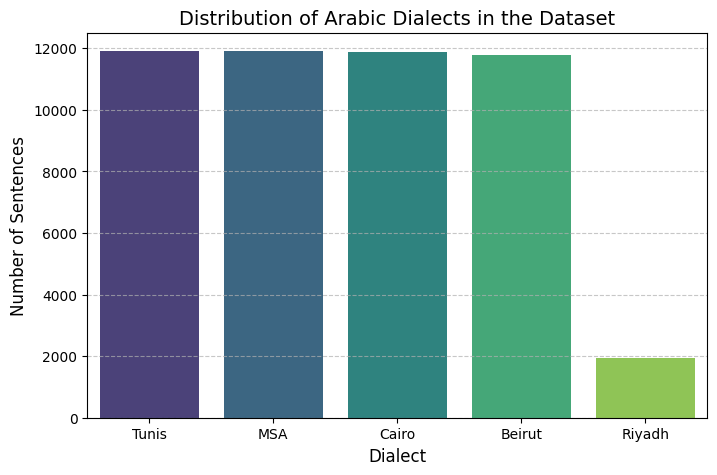

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Print exact counts and percentages for each dialect
dialect_counts = df['label'].value_counts()
dialect_percentages = df['label'].value_counts(normalize=True) * 100

distribution_df = pd.DataFrame({
    'Count': dialect_counts,
    'Percentage (%)': dialect_percentages.round(2)
})
print("Class Distribution across the 5 Dialects:")
display(distribution_df)

# 2. Plot the distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', order=dialect_counts.index, palette='viridis')
plt.title('Distribution of Arabic Dialects in the Dataset', fontsize=14)
plt.xlabel('Dialect', fontsize=12)
plt.ylabel('Number of Sentences', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Step 2.1: Diagnosis of Class Imbalance & Corrective Action

**1. Observation (Problem Diagnosis):**
From the distribution plot and table above, we observe a **severe class imbalance**:
* `Tunis`, `MSA`, `Cairo`, and `Beirut` each contain approximately **11,800 – 11,900 sentences** (~24% each).
* `Riyadh` contains only **1,943 sentences** (3.93% of the dataset).

**2. Root Cause Analysis:**
Upon investigating the structure of the **MADAR Corpus**, it is divided into two main subsets:
* **MADAR Corpus-6:** Contains **12,000 sentences** per city across 5 major cities (`Cairo`, `Beirut`, `Tunis`, `Doha`, `Rabat`) + `MSA`.
* **MADAR Corpus-26:** Contains only **2,000 sentences** per city across 25 cities (which includes `Riyadh`).

Because `Riyadh` belongs solely to Corpus-26, including it alongside cities from Corpus-6 created a 6:1 data imbalance, which would bias the classification models against the Gulf dialect.

**3. Corrective Action:**
To maintain a large, rich, and **100% balanced dataset** without losing data through undersampling, we will replace **`Riyadh`** with **`Doha`** (which represents the Gulf dialect in MADAR Corpus-6 with 12,000 sentences). We will reload `Doha` from the raw directory, apply the same text cleaning pipeline, and update our processed dataset.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 4.1 MB/s eta 0:00:00
Updated balanced dataset saved! Total rows: 58416



,Count,Percentage (%)
label,,
Tunis,11900,20.37
Cairo,11796,20.19
MSA,11790,20.18
Beirut,11660,19.96
Doha,11270,19.29


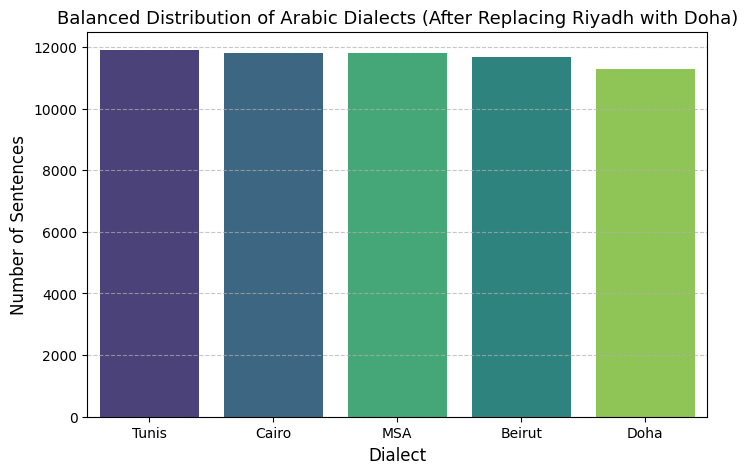

In [4]:
# Install pyarabic if not already installed in this session
!pip install pyarabic -q

import re
import pyarabic.araby as araby

raw_data_path = '/content/drive/MyDrive/arabic-dialect-classification/data/raw'
processed_file_path = '/content/drive/MyDrive/arabic-dialect-classification/data/processed/cleaned_dataset.csv'

# 1. Remove 'Riyadh' from the current DataFrame
df_filtered = df[df['label'] != 'Riyadh'].copy()

# 2. Load 'Doha' from raw files
doha_dfs = []
for root, dirs, files in os.walk(raw_data_path):
    for file in files:
        if "MADAR.corpus.Doha.tsv" in file:
            doha_path = os.path.join(root, file)
            temp_df = pd.read_csv(doha_path, sep='\t', header=None, names=['text'])
            temp_df['label'] = 'Doha'
            doha_dfs.append(temp_df)

doha_df = pd.concat(doha_dfs, ignore_index=True)

# 3. Clean 'Doha' text using the exact same preprocessing function
def clean_arabic_text(text):
    text = str(text)
    text = araby.strip_tashkeel(text)
    text = araby.strip_tatweel(text)
    text = re.sub(r'[إأآ]', 'ا', text)
    text = re.sub(r'ة', 'ه', text)
    text = re.sub(r'ى', 'ي', text)
    text = re.sub(r'[^\w\s\u0621-\u064A]', ' ', text)
    text = re.sub(r'[0-9a-zA-Z]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

doha_df.dropna(subset=['text'], inplace=True)
doha_df.drop_duplicates(subset=['text'], inplace=True)
doha_df['cleaned_text'] = doha_df['text'].apply(clean_arabic_text)

# 4. Combine with the main DataFrame and clean up
df = pd.concat([df_filtered, doha_df], ignore_index=True)
df.dropna(subset=['cleaned_text'], inplace=True)
df = df[df['cleaned_text'].str.strip() != '']
df.drop_duplicates(subset=['cleaned_text'], inplace=True)
df.reset_index(drop=True, inplace=True)

# 5. Update the saved CSV file in Drive
df.to_csv(processed_file_path, index=False)
print(f"Updated balanced dataset saved! Total rows: {len(df)}\n")

# 6. Re-verify Class Distribution and Plot (without FutureWarning)
dialect_counts = df['label'].value_counts()
dialect_percentages = df['label'].value_counts(normalize=True) * 100

balanced_dist_df = pd.DataFrame({
    'Count': dialect_counts,
    'Percentage (%)': dialect_percentages.round(2)
})
display(balanced_dist_df)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', hue='label', order=dialect_counts.index, palette='viridis', legend=False)
plt.title('Balanced Distribution of Arabic Dialects (After Replacing Riyadh with Doha)', fontsize=13)
plt.xlabel('Dialect', fontsize=12)
plt.ylabel('Number of Sentences', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Step 2.2: Sanity Check for Nulls and Duplicates After Adding Doha

In [5]:
# 1. Check for standard missing values (NaN)
print("Missing values (NaN) per column:")
print(df.isnull().sum())
print("-" * 40)

# 2. Check for empty strings or whitespace-only sentences in cleaned_text
empty_strings = (df['cleaned_text'].str.strip() == '').sum()
print(f"Empty/Whitespace-only rows in 'cleaned_text': {empty_strings}")
print("-" * 40)

# 3. Check for duplicates in raw 'text' and 'cleaned_text'
raw_duplicates = df.duplicated(subset=['text']).sum()
cleaned_duplicates = df.duplicated(subset=['cleaned_text']).sum()

print(f"Duplicate rows based on raw 'text': {raw_duplicates}")
print(f"Duplicate rows based on 'cleaned_text': {cleaned_duplicates}")
print("-" * 40)

# 4. Display the first 5 rows of the newly added 'Doha' dialect to verify
print("Sample rows from Doha dialect:")
display(df[df['label'] == 'Doha'].head())

Missing values (NaN) per column:
text            0
label           0
cleaned_text    0
dtype: int64
----------------------------------------
Empty/Whitespace-only rows in 'cleaned_text': 0
----------------------------------------
Duplicate rows based on raw 'text': 0
Duplicate rows based on 'cleaned_text': 0
----------------------------------------
Sample rows from Doha dialect:


,text,label,cleaned_text
47146,موجود في نهاية الممر، بجيب لك شوي الحين. اذا ا...,Doha,موجود في نهايه الممر بجيب لك شوي الحين اذا احت...
47147,تسوي تعديلات؟,Doha,تسوي تعديلات
47148,بغينا طاولة يم الدريشة.,Doha,بغينا طاوله يم الدريشه
47149,هو ذاك الصوب، بالضبط جدام استعلامات السياح بال...,Doha,هو ذاك الصوب بالضبط جدام استعلامات السياح بالضبط
47150,ما قط سمعت بهالعنوان في هالمنطقة من قبل.,Doha,ما قط سمعت بهالعنوان في هالمنطقه من قبل


### Step 3: Exploratory Data Analysis (EDA) - Sentence Length Analysis

Statistical Summary of Word and Character Counts:


,word_count,char_count
count,58416.00,58416.00
mean,5.77,29.00
std,3.29,17.47
min,1.00,1.00
25%,4.00,18.00
50%,5.00,25.00
75%,7.00,36.00
max,50.00,258.00


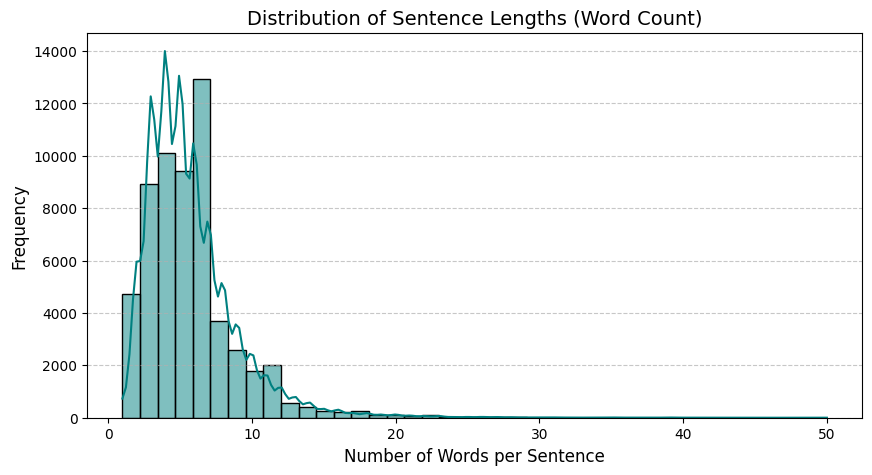

In [6]:
# 1. Calculate word count and character count for each cleaned sentence
df['word_count'] = df['cleaned_text'].apply(lambda x: len(str(x).split()))
df['char_count'] = df['cleaned_text'].apply(lambda x: len(str(x)))

# 2. Display statistical summary (min, max, mean, quartiles)
print("Statistical Summary of Word and Character Counts:")
display(df[['word_count', 'char_count']].describe().round(2))

# 3. Plot the distribution of word counts
plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=40, kde=True, color='teal')
plt.title('Distribution of Sentence Lengths (Word Count)', fontsize=14)
plt.xlabel('Number of Words per Sentence', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Step 3.1: Inspect Extremely Short Sentences (1 Word or Very Few Characters)

In [7]:
# 1. Check sentences with 2 characters or less (likely noise)
very_short_chars = df[df['char_count'] <= 2]
print(f"Number of sentences with <= 2 characters: {len(very_short_chars)}")
display(very_short_chars[['text', 'cleaned_text', 'label', 'char_count']].head(15))

print("-" * 50)

# 2. Check a sample of single-word sentences (with more than 2 characters)
single_word = df[(df['word_count'] == 1) & (df['char_count'] > 2)]
print(f"Number of single-word sentences (> 2 chars): {len(single_word)}")
display(single_word[['text', 'cleaned_text', 'label', 'char_count']].head(15))

Number of sentences with <= 2 characters: 15


,text,cleaned_text,label,char_count
418,لا.,لا,Tunis,2
848,اي.,اي,Tunis,2
11062,جو.,جو,Tunis,2
20393,قف.,قف,Cairo,2
24217,صح.,صح,Beirut,2
27816,صف .,صف,Beirut,2
32474,شو؟,شو,Beirut,2
34548,ب؟,ب,Beirut,1
41391,لص .,لص,MSA,2
44234,آه ؟,اه,MSA,2


--------------------------------------------------
Number of single-word sentences (> 2 chars): 429


,text,cleaned_text,label,char_count
88,تكسيات؟,تكسيات,Tunis,6
91,تفضل.,تفضل,Tunis,4
122,سكر؟,سكر,Tunis,3
132,تبعني.,تبعني,Tunis,5
211,للقراية.,للقرايه,Tunis,7
244,شفت؟,شفت,Tunis,3
262,ايامات.,ايامات,Tunis,6
288,يقرصو.,يقرصو,Tunis,5
304,معلم.,معلم,Tunis,4
389,هدية؟,هديه,Tunis,4


### Step 3.2: Analysis of Short Sentences & Filtering Decision

**1. Observation:**
* **Single-word sentences (> 2 characters):** Inspecting the 429 single-word entries reveals highly dialect-specific vocabulary (e.g., `يزيك`, `استعجالي`, `يقرصو`, `ايامات` in Tunis). Removing them would strip away valuable lexical features.
* **Two-character sentences:** Even 2-character entries contain strong dialectal markers such as `شو` (Beirut) and `صج` (Doha).
* **Single-character entries (`char_count == 1`):** Only **1 row** consists of a single isolated character (`ب`), which carries no dialectal meaning and acts as noise.

**2. Action:**
We will retain all valid 1-word and 2-character sentences, and strictly filter out entries where `char_count <= 1`.

In [8]:
# Remove rows where cleaned_text has only 1 character
df = df[df['char_count'] > 1].copy()
df.reset_index(drop=True, inplace=True)

print(f"Dataset size after removing single-character noise: {len(df)}")
print(f"New minimum character count: {df['char_count'].min()}")

# Save the updated dataframe (keeping only the main 3 columns in the CSV file)
processed_file_path = '/content/drive/MyDrive/arabic-dialect-classification/data/processed/cleaned_dataset.csv'
df[['text', 'label', 'cleaned_text']].to_csv(processed_file_path, index=False)
print("Updated dataset saved successfully to Drive! 🚀")

Dataset size after removing single-character noise: 58415
New minimum character count: 2
Updated dataset saved successfully to Drive! 🚀


### Step 4: Exploratory Data Analysis (EDA) - Most Frequent Words per Dialect

In [9]:
from collections import Counter

# Function to get top N most frequent words for a given dialect
def get_top_words(dataframe, dialect, n=10):
    text_series = dataframe[dataframe['label'] == dialect]['cleaned_text']
    all_words = ' '.join(text_series).split()
    return Counter(all_words).most_common(n)

# Display top 10 words for each of the 5 dialects in a clean table
top_words_dict = {}
for dialect in df['label'].unique():
    top_words = get_top_words(df, dialect, n=10)
    # Format as "word (count)"
    top_words_dict[dialect] = [f"{word} ({count})" for word, count in top_words]

top_words_df = pd.DataFrame(top_words_dict)
top_words_df.index = [f"Rank {i+1}" for i in range(10)]

print("Top 10 Most Frequent Words per Dialect (Before any Stopword Filtering):")
display(top_words_df)

Top 10 Most Frequent Words per Dialect (Before any Stopword Filtering):


,Tunis,Cairo,Beirut,MSA,Doha
Rank 1,في (1624),من (1629),بتريد (1187),من (3095),في (1742)
Rank 2,يعيشك (1218),ممكن (1540),بدي (1115),هل (2723),لو (1545)
Rank 3,نحب (1052),في (1477),من (905),ان (2234),سمحت (1521)
Rank 4,هذا (919),ده (1282),ما (830),في (1798),ممكن (1139)
Rank 5,تنجم (688),انا (1216),فيك (827),فضلك (1537),من (833)
Rank 6,من (663),عايز (966),ازا (735),الي (1101),هذي (799)
Rank 7,و (615),لو (881),اذا (676),هذا (1013),حق (689)
Rank 8,علي (598),سمحت (798),في (657),علي (963),بغيت (686)
Rank 9,ما (582),و (790),و (642),اريد (768),علي (655)
Rank 10,نجم (567),فضلك (766),شي (617),ما (627),ما (545)


### Step 4.1: Lexical Analysis Insights & Stopword Strategy

**1. Observation:**
Inspecting the top 10 raw words across the 5 dialects reveals two distinct categories:
* **Dialect-agnostic functional words:** Prepositions and conjunctions such as (`في`, `من`, `علي`, `و`, `ما`, `انا`, `لو`) appear heavily across all dialects without offering discriminative power.
* **Strong dialectal markers:** Even within the top 10, clear dialectal fingerprints emerge:
  * **Tunis:** `يعيشك`, `نحب`, `تنجم`, `نجم`
  * **Cairo:** `ده`, `عايز`, `ممكن`
  * **Beirut:** `بتريد`, `بدي`, `فيك`, `ازا`, `شي`
  * **MSA:** `هل`, `اريد`, `هذا`
  * **Doha:** `هذي`, `حق`, `بغيت`

**2. Engineering Decision (Why We Do Not Blindly Remove Stopwords):**
Standard Arabic stopword lists (e.g., NLTK) automatically strip demonstrative pronouns, question words, and negations (such as `ده`, `هذي`, `هذا`, `هل`, `شي`, `مش`, `مو`). In dialect classification, these words are prime indicators of the dialect. Therefore:
* We **preserve all words** in `cleaned_text` for model training so contextual and syntactic cues remain intact.
* For **EDA visualization only**, we filter out a minimal list of neutral prepositions/conjunctions to clearly highlight the unique lexical markers of each dialect.

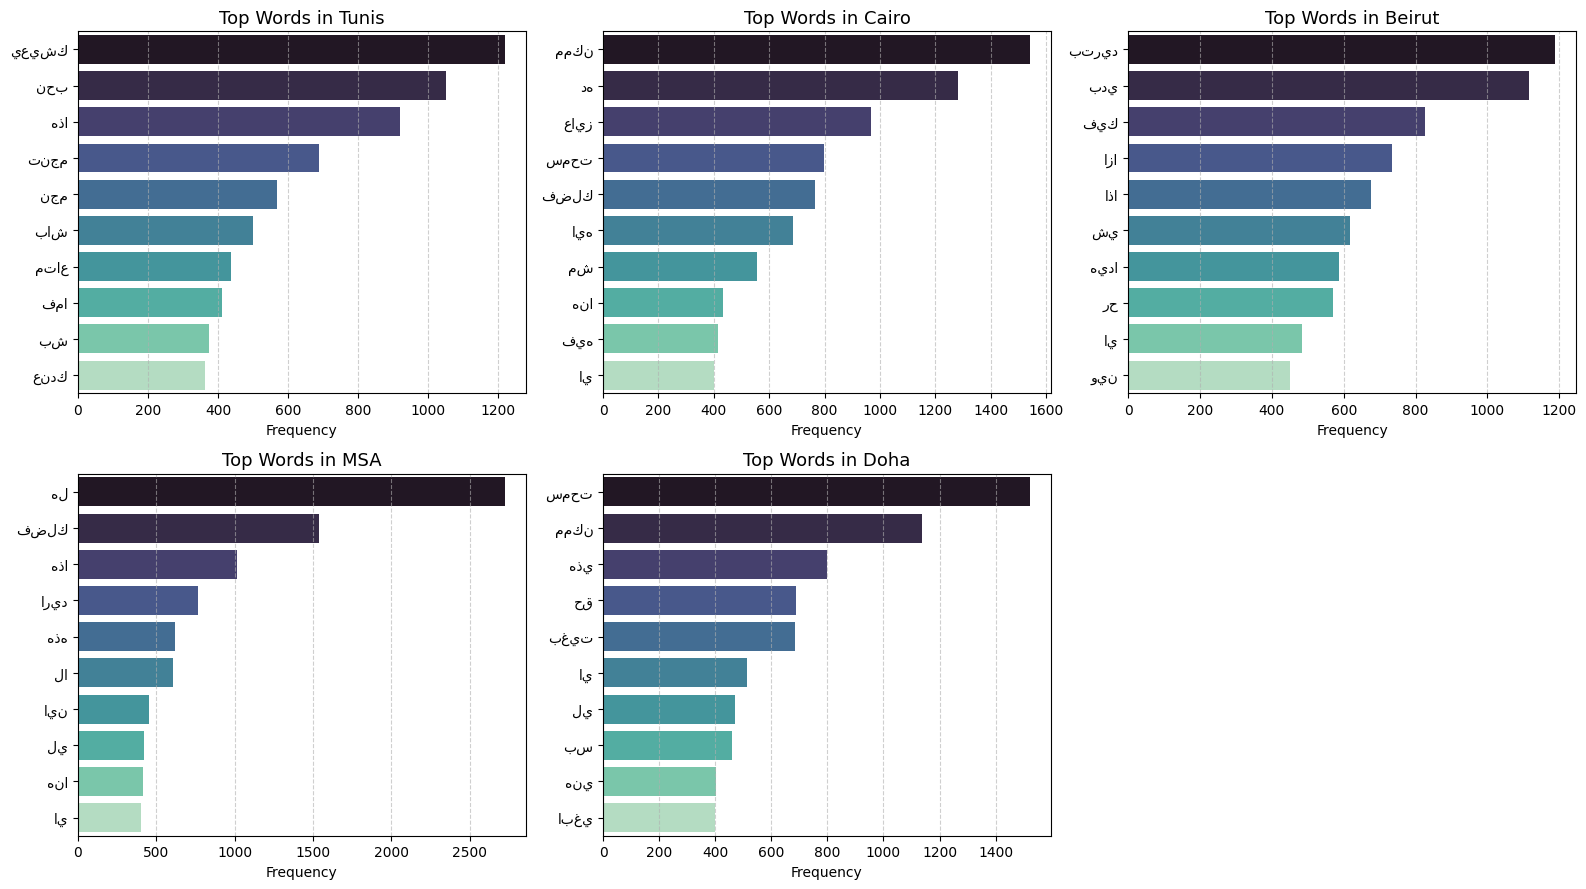

In [10]:
# Minimal list of neutral Arabic prepositions/conjunctions to exclude ONLY for visualization
neutral_stopwords = {'في', 'من', 'علي', 'و', 'ما', 'ان', 'انا', 'لو', 'الي', 'اللي', 'عن', 'مع', 'او', 'كل'}

def get_filtered_top_words(dataframe, dialect, n=10):
    text_series = dataframe[dataframe['label'] == dialect]['cleaned_text']
    # Filter out neutral stopwords only during counting
    words = [w for w in ' '.join(text_series).split() if w not in neutral_stopwords]
    return Counter(words).most_common(n)

# Plot Top 10 distinctive words for each dialect
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

dialects = df['label'].unique()

for i, dialect in enumerate(dialects):
    top_words = get_filtered_top_words(df, dialect, n=10)
    words_df = pd.DataFrame(top_words, columns=['Word', 'Count'])

    sns.barplot(data=words_df, x='Count', y='Word', hue='Word', ax=axes[i], palette='mako', legend=False)
    axes[i].set_title(f'Top Words in {dialect}', fontsize=13)
    axes[i].set_xlabel('Frequency')
    axes[i].set_ylabel('')
    axes[i].grid(axis='x', linestyle='--', alpha=0.6)

# Hide the 6th empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

### Step 4.2: Fixing Arabic Text Rendering in Matplotlib (`arabic_reshaper` & `python-bidi`)

**1. Observation:**
In the plot above, the Arabic words on the y-axis appear **disconnected and reversed** (rendered Left-to-Right instead of Right-to-Left), because `matplotlib` does not natively support cursive shaping or bidirectional (BiDi) text rendering.

**2. Corrective Action:**
We install and apply two specialized libraries ONLY for the visualization labels:
* `arabic-reshaper`: Reconnects isolated Arabic letters into their proper contextual cursive forms.
* `python-bidi`: Applies the bidirectional algorithm so the reshaped text displays correctly from Right to Left.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 9.0 MB/s eta 0:00:00


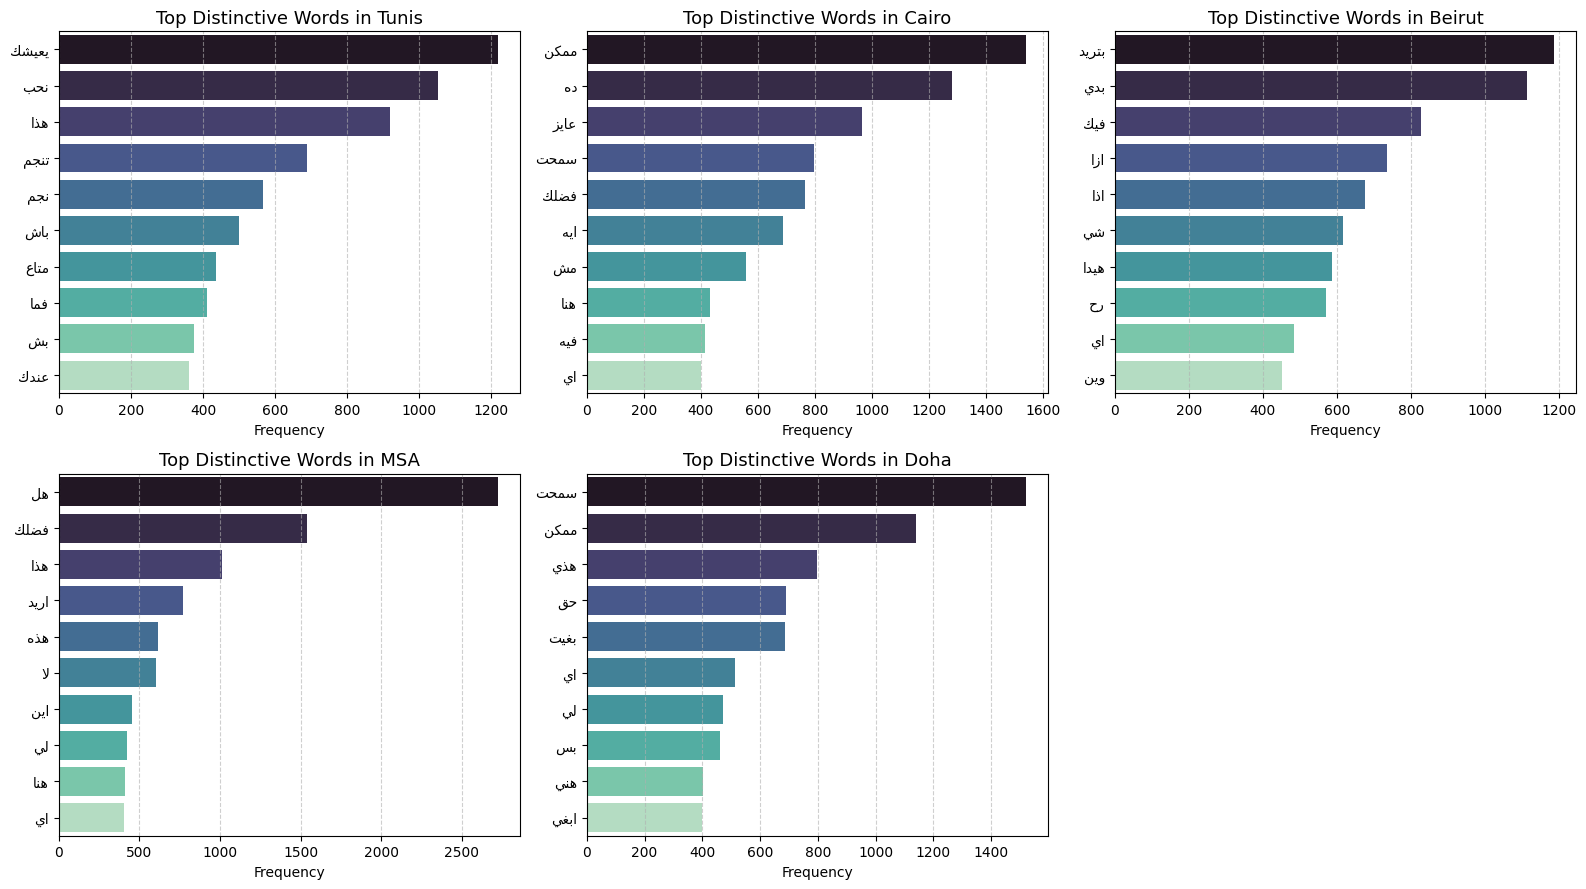

In [11]:
# Install Arabic text rendering libraries for Matplotlib
!pip install arabic-reshaper python-bidi -q

import arabic_reshaper
from bidi.algorithm import get_display

# Helper function to fix Arabic text display on plots
def fix_arabic_label(text):
    reshaped_text = arabic_reshaper.reshape(str(text))
    return get_display(reshaped_text)

# Re-plot Top 10 distinctive words with properly rendered Arabic labels
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

dialects = df['label'].unique()

for i, dialect in enumerate(dialects):
    top_words = get_filtered_top_words(df, dialect, n=10)
    words_df = pd.DataFrame(top_words, columns=['Word', 'Count'])

    # Apply the Arabic rendering fix to the 'Word' column for plotting
    words_df['Word_Display'] = words_df['Word'].apply(fix_arabic_label)

    sns.barplot(data=words_df, x='Count', y='Word_Display', hue='Word_Display', ax=axes[i], palette='mako', legend=False)
    axes[i].set_title(f'Top Distinctive Words in {dialect}', fontsize=13)
    axes[i].set_xlabel('Frequency')
    axes[i].set_ylabel('')
    axes[i].grid(axis='x', linestyle='--', alpha=0.6)

# Hide the 6th empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

### Step 5: Stratified Data Splitting (Train / Validation / Test)

In [12]:
from sklearn.model_selection import train_test_split

# Keep only the essential columns for modeling
final_df = df[['cleaned_text', 'label']].copy()

# 1. First split: 80% Train, 20% Temp (Validation + Test) with stratification
train_df, temp_df = train_test_split(
    final_df,
    test_size=0.20,
    random_state=42,
    stratify=final_df['label']
)

# 2. Second split: Split the 20% Temp equally into 10% Validation and 10% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

# 3. Verify sizes and class distribution across splits
print(f"Total dataset size : {len(final_df)}")
print(f"Training set (80%) : {len(train_df)}")
print(f"Validation set (10%): {len(val_df)}")
print(f"Test set (10%)     : {len(test_df)}\n")

split_verification = pd.DataFrame({
    'Train Count': train_df['label'].value_counts(),
    'Train (%)': (train_df['label'].value_counts(normalize=True) * 100).round(2),
    'Val Count': val_df['label'].value_counts(),
    'Val (%)': (val_df['label'].value_counts(normalize=True) * 100).round(2),
    'Test Count': test_df['label'].value_counts(),
    'Test (%)': (test_df['label'].value_counts(normalize=True) * 100).round(2),
})

print("Verification of Stratified Class Distribution across Splits:")
display(split_verification)

# 4. Save the splits to the processed folder in Google Drive
processed_dir = '/content/drive/MyDrive/arabic-dialect-classification/data/processed'
train_df.to_csv(os.path.join(processed_dir, 'train.csv'), index=False)
val_df.to_csv(os.path.join(processed_dir, 'val.csv'), index=False)
test_df.to_csv(os.path.join(processed_dir, 'test.csv'), index=False)

print("\nTrain, Validation, and Test sets saved successfully to Google Drive! 🚀")

Total dataset size : 58415
Training set (80%) : 46732
Validation set (10%): 5841
Test set (10%)     : 5842

Verification of Stratified Class Distribution across Splits:


,Train Count,Train (%),Val Count,Val (%),Test Count,Test (%)
label,,,,,,
Beirut,9327,19.96,1166,19.96,1166,19.96
Cairo,9437,20.19,1179,20.18,1180,20.20
Doha,9016,19.29,1127,19.29,1127,19.29
MSA,9432,20.18,1179,20.18,1179,20.18
Tunis,9520,20.37,1190,20.37,1190,20.37



Train, Validation, and Test sets saved successfully to Google Drive! 🚀
